In [48]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader, random_split
from torchvision import datasets


device= torch.device('cuda' if torch.cuda.is_available() else 'cpu')

SEED= 21
num_epochs=15
batch_size=32
learning_rate=0.001

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])




In [49]:
!unzip -tk "/content/ArASL_Database_54K_Final.zip"

UnZip 6.00 of 20 April 2009, by Debian. Original by Info-ZIP.

Usage: unzip [-Z] [-opts[modifiers]] file[.zip] [list] [-x xlist] [-d exdir]
  Default action is to extract files in list, except those in xlist, to exdir;
  file[.zip] may be a wildcard.  -Z => ZipInfo mode ("unzip -Z" for usage).

  -p  extract files to pipe, no messages     -l  list files (short format)
  -f  freshen existing files, create none    -t  test compressed archive data
  -u  update files, create if necessary      -z  display archive comment only
  -v  list verbosely/show version info       -T  timestamp archive to latest
  -x  exclude files that follow (in xlist)   -d  extract files into exdir
modifiers:
  -n  never overwrite existing files         -q  quiet mode (-qq => quieter)
  -o  overwrite files WITHOUT prompting      -a  auto-convert any text files
  -j  junk paths (do not make directories)   -aa treat ALL files as text
  -U  use escapes for all non-ASCII Unicode  -UU ignore any Unicode fields
  -C  mat

In [58]:
full_dataset = datasets.ImageFolder(
    "/content/ArASL/ArASL_Database_54K_Final",
    transform=transform
)
torch.manual_seed(SEED)

train_size = int(0.7 * len(full_dataset))
val_size = int(0.15 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size]
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

classes = full_dataset.classes

class ConvNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)

        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))

        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(256, len(classes))

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x


model = ConvNet().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

loss_list = []
val_loss_list = []
val_acc_list = []
best_val_loss = float('inf')
n_total_steps = len(train_loader)

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / n_total_steps
    loss_list.append(epoch_loss)


    model.eval()
    val_loss, val_correct = 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            out = model(images)
            val_loss += criterion(out, labels).item()
            val_correct += (out.argmax(1) == labels).sum().item()

    val_loss /= len(val_loader)
    val_acc = 100 * val_correct / len(val_dataset)
    val_loss_list.append(val_loss)
    val_acc_list.append(val_acc)


    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), 'arasl_model.pth')

    print(f'Epoch [{epoch+1}/{num_epochs}] '
          f'Train Loss: {epoch_loss:.4f} | '
          f'Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%')

Epoch [1/15] Train Loss: 1.4987 | Val Loss: 0.5297 | Val Acc: 83.88%
Epoch [2/15] Train Loss: 0.5168 | Val Loss: 0.2542 | Val Acc: 93.54%
Epoch [3/15] Train Loss: 0.3293 | Val Loss: 0.1715 | Val Acc: 95.58%
Epoch [4/15] Train Loss: 0.2527 | Val Loss: 0.1657 | Val Acc: 95.65%
Epoch [5/15] Train Loss: 0.2101 | Val Loss: 0.1885 | Val Acc: 94.93%
Epoch [6/15] Train Loss: 0.1768 | Val Loss: 0.1430 | Val Acc: 96.34%
Epoch [7/15] Train Loss: 0.1490 | Val Loss: 0.1223 | Val Acc: 96.83%
Epoch [8/15] Train Loss: 0.1362 | Val Loss: 0.1497 | Val Acc: 96.02%
Epoch [9/15] Train Loss: 0.1169 | Val Loss: 0.1265 | Val Acc: 96.72%
Epoch [10/15] Train Loss: 0.1135 | Val Loss: 0.1199 | Val Acc: 96.98%
Epoch [11/15] Train Loss: 0.0988 | Val Loss: 0.1165 | Val Acc: 97.21%
Epoch [12/15] Train Loss: 0.0896 | Val Loss: 0.1291 | Val Acc: 97.06%
Epoch [13/15] Train Loss: 0.0867 | Val Loss: 0.1309 | Val Acc: 97.04%
Epoch [14/15] Train Loss: 0.0781 | Val Loss: 0.1234 | Val Acc: 97.18%
Epoch [15/15] Train Loss: 0.0

In [59]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Test Accuracy: {100 * correct / total:.2f}%')

Test Accuracy: 97.35%


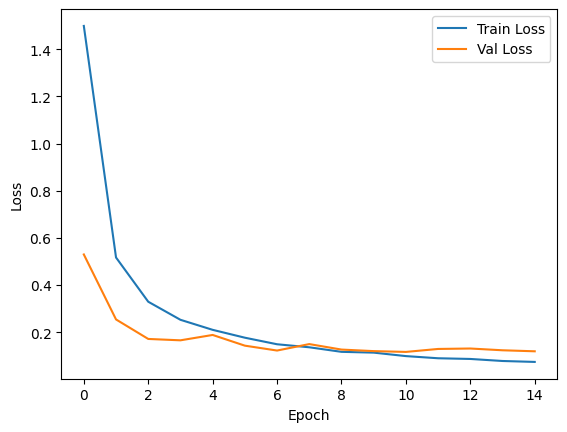

In [60]:
plt.plot(loss_list, label='Train Loss')
plt.plot(val_loss_list, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()



In [61]:
class_correct = [0] * len(classes)
class_total = [0] * len(classes)

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        for i in range(len(labels)):
            label = labels[i].item()
            class_total[label] += 1
            if predicted[i] == labels[i]:
                class_correct[label] += 1

for i in range(len(classes)):
    print(f'{classes[i]}: {100 * class_correct[i] / class_total[i]:.1f}%')

ain: 99.4%
al: 98.1%
aleff: 99.6%
bb: 96.4%
dal: 98.7%
dha: 94.0%
dhad: 98.5%
fa: 94.8%
gaaf: 97.0%
ghain: 98.7%
ha: 96.8%
haa: 95.2%
jeem: 94.1%
kaaf: 97.1%
khaa: 98.4%
la: 99.6%
laam: 99.6%
meem: 98.8%
nun: 98.4%
ra: 96.5%
saad: 97.5%
seen: 97.5%
sheen: 95.5%
ta: 96.7%
taa: 97.6%
thaa: 97.5%
thal: 97.5%
toot: 98.5%
waw: 98.2%
ya: 98.8%
yaa: 99.5%
zay: 89.3%


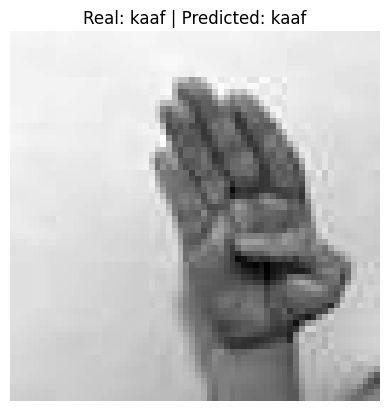

In [62]:
images, labels = next(iter(test_loader))
images = images.to(device)

outputs = model(images)
_, predicted = torch.max(outputs, 1)

plt.imshow(images[0].cpu().squeeze(), cmap='gray')
plt.title(f'Real: {classes[labels[0]]} | Predicted: {classes[predicted[0]]}')
plt.axis('off')
plt.show()

In [63]:
model = ConvNet().to(device)
model.load_state_dict(torch.load('arasl_model.pth'))
model.eval()

ConvNet(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=256, out_features=32, bias=True)
)